## Step 1: Data Exploration & Cleaning
Imports & Setup

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

### Data loading and initial inspection

In [3]:
df = pd.read_csv("data/project_dataset.csv", sep=";")
df.head()

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141.0,870,5.0,NaN,289.0,11.24780854,...,110.0,6.51,44.0,8.0,36.13445378,31.09243697,10.92436975,15.96638655,"5,04",0.840336134
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56.0,406.0,1.0,NaN,213.0,8.479968701,...,32.0,5.363539095,9.0,4.0,20.0,35.0,16.66666667,16.66666667,8.333333333,3.333333333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166.0,226.0,0.0,NaN,21.0,6.23968254,...,11.0,2.938053097,6.0,1.0,22.22222222,27.77777778,16.66666667,16.66666667,5.555555556,11.11111111
3,2018-01,National,PARIS MONTPARNASSE,NANTES,216.21,508.0,3.0,NaN,71.0,7.235211268,...,39.0,5.292211221,18.0,NaN,33.33333333,22.22222222,16.66666667,20.37037037,5.555555556,1.851851852
4,2018-01,National,POITIERS,PARIS MONTPARNASSE,94.0,472.0,4.0,NaN,224.0,6.784672619,...,42.0,4.882371795,10.0,0.0,15.78947368,45.61403509,NaN,15.78947368,1.754385965,1.754385965


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12070 entries, 0 to 12069
Data columns (total 26 columns):
 #   Column                                                                                       Non-Null Count  Dtype 
---  ------                                                                                       --------------  ----- 
 0   Date                                                                                         12010 non-null  object
 1   Service                                                                                      11830 non-null  object
 2   Gare de départ                                                                               12011 non-null  object
 3   Gare d'arrivée                                                                               12011 non-null  object
 4   Durée moyenne du trajet                                                                      11830 non-null  object
 5   Nombre de circulations prévues         

### Missing values and duplicates handling

In [5]:
colonnes_inutiles = [col for col in df.columns if "Commentaire" in col]
df = df.drop(columns=colonnes_inutiles)

nouveaux_noms = {
    "Date": "date",
    "Service": "service",
    "Gare de départ": "gare_depart",
    "Gare d'arrivée": "gare_arrivee",
    "Durée moyenne du trajet": "duree_moyenne_trajet",
    "Nombre de circulations prévues": "circulations_prevues",
    "Nombre de trains annulés": "trains_annules",
    "Nombre de trains en retard au départ": "trains_retard_depart",
    "Retard moyen des trains en retard au départ": "retard_moyen_trains_retard_depart",
    "Retard moyen de tous les trains au départ": "retard_moyen_tous_depart",
    "Nombre de trains en retard à l'arrivée": "trains_retard_arrivee",
    "Retard moyen des trains en retard à l'arrivée": "retard_moyen_trains_retard_arrivee",
    "Retard moyen de tous les trains à l'arrivée": "retard_moyen_tous_arrivee",
    "Nombre trains en retard > 15min": "retard_sup_15min",
    "Nombre trains en retard > 30min": "retard_sup_30min",
    "Nombre trains en retard > 60min": "retard_sup_60min",
    "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)": "retard_moyen_sup_15min",
    "Prct retard pour causes externes": "prct_causes_externes",
    "Prct retard pour cause infrastructure": "prct_infrastructure",
    "Prct retard pour cause gestion trafic": "prct_gestion_trafic",
    "Prct retard pour cause matériel roulant": "prct_materiel_roulant",
    "Prct retard pour cause gestion en gare et réutilisation de matériel": "prct_gestion_gare",
    "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)": "prct_voyageurs",
}

df = df.replace(["", "NaN", "nan", "N/A", "NA", "null", "None", " "], np.nan)
df = df.dropna()

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna(subset=["Date"])
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Date"] = df["Date"].dt.strftime("%Y-%m-%d")

text_cols = ["Date", "Service", "Gare de départ", "Gare d'arrivée"]
for col in text_cols:
    df[col] = df[col].astype(str).str.strip().str.title()

num_cols = [c for c in df.columns if c not in text_cols and c not in ["Year", "Month"]]
for col in num_cols:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", "."), errors="coerce")

df = df.dropna()

for col in num_cols:
    df = df[df[col] >= 0]

df = df[df["Nombre trains en retard > 60min"] <= df["Nombre trains en retard > 30min"]]
df = df[df["Nombre trains en retard > 30min"] <= df["Nombre trains en retard > 15min"]]
df = df[
    df["Nombre trains en retard > 15min"]
    <= df["Nombre de trains en retard à l'arrivée"]
]
df = df[df["Nombre de trains annulés"] <= df["Nombre de circulations prévues"]]

df = df.drop_duplicates(subset=["Date", "Gare de départ", "Gare d'arrivée"])
df = df.drop_duplicates()

df = df.rename(columns=nouveaux_noms)
df = df.rename(columns={"Year": "year", "Month": "month"})

df.to_csv("cleaned_dataset.csv", index=False)
print("Dimensions après nettoyage:", df.shape)

Dimensions après nettoyage: (6687, 25)


### Data Visualization & Analysis

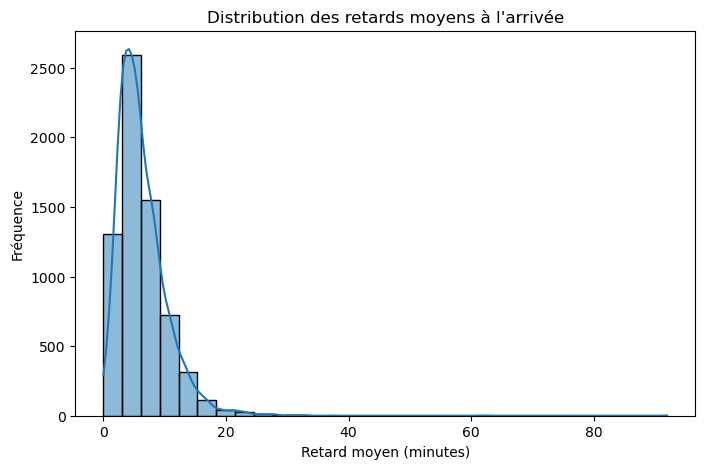

In [6]:
plt.figure(figsize=(8, 5))
sns.histplot(df["retard_moyen_tous_arrivee"], bins=30, kde=True)
plt.title("Distribution des retards moyens à l'arrivée")
plt.xlabel("Retard moyen (minutes)")
plt.ylabel("Fréquence")
plt.show()

### Interpretation :
On observe que les retard des différent trains sont majoritairement très faible, entre 0 et 10 minutes et que presque aucun ne depassent la barre des 20 minutes de retard.

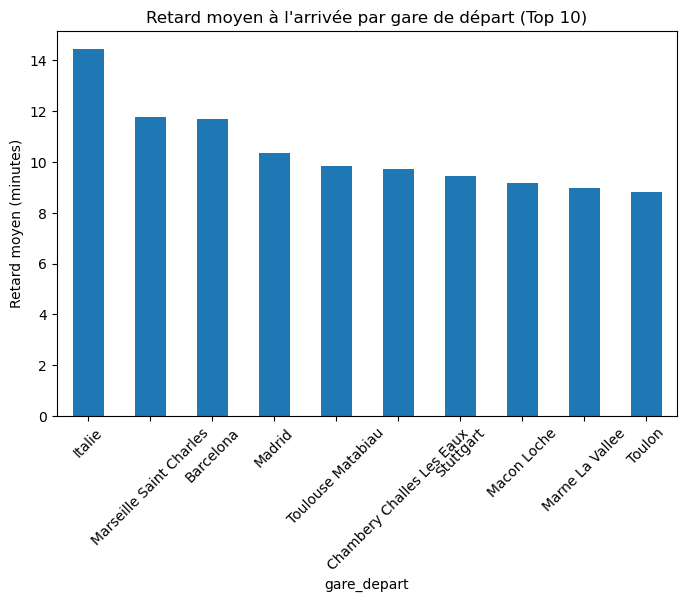

In [7]:
top_gares_retard = (
    df.groupby("gare_depart")["retard_moyen_tous_arrivee"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)
plt.figure(figsize=(8, 5))
top_gares_retard.plot(kind="bar")
plt.title("Retard moyen à l'arrivée par gare de départ (Top 10)")
plt.ylabel("Retard moyen (minutes)")
plt.xticks(rotation=45)
plt.show()



### Interpretation :
On peut observer sur se graphique les gares avec le plus de retard moyen au départ, la plus représenter ici étant la gare d'Italie avec une moyenne de 14 minutes de retard.

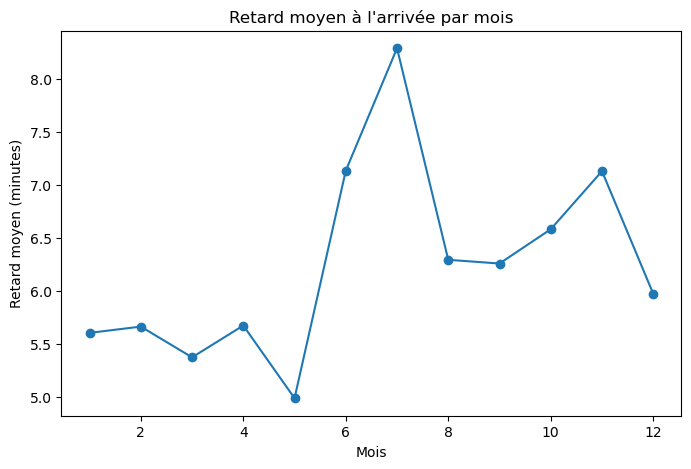

In [8]:
df["date"] = df["date"].astype(str).str.replace(" ", "-", regex=False)
df["date"] = pd.to_datetime(df["date"], format="mixed", errors="coerce")
df["mois"] = df["date"].dt.month

retard_par_mois = df.groupby("mois")["retard_moyen_tous_arrivee"].mean()
plt.figure(figsize=(8, 5))
retard_par_mois.plot(marker="o")
plt.title("Retard moyen à l'arrivée par mois")
plt.xlabel("Mois")
plt.ylabel("Retard moyen (minutes)")
plt.show()

### Interpretation :
Se graphique presente le retard moyen des train en fonction du mois de l'année. On peut donc voir que les début d'année sont plutot calme avec un fort pic de retard lors du mois de mai, la tendance retombe ensuite en aout avant de se stabiliser autour de 6.5 minute de retard en moyenne en fin d'année.

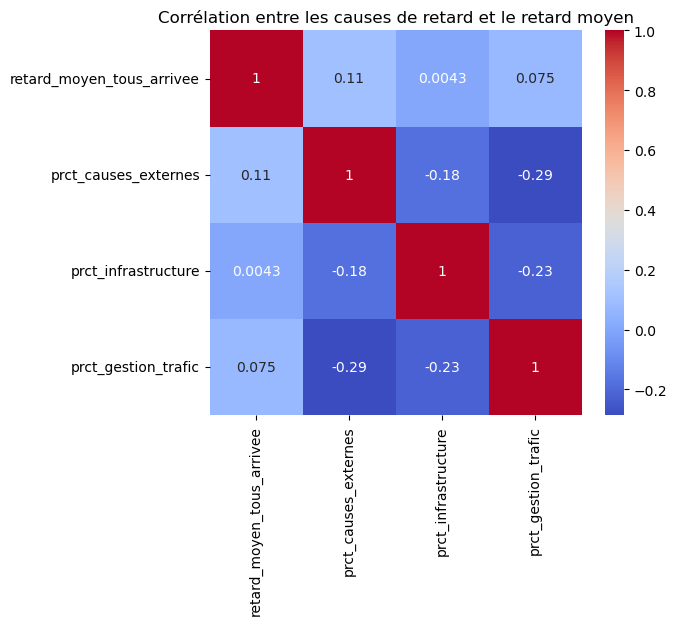

In [9]:
correlation_retards = df[
    [
        "retard_moyen_tous_arrivee",
        "prct_causes_externes",
        "prct_infrastructure",
        "prct_gestion_trafic",
    ]
].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(correlation_retards, annot=True, cmap="coolwarm")
plt.title("Corrélation entre les causes de retard et le retard moyen")
plt.show()

### Interpretation :
Se tableau présente la corrélation entre les causes de retard et le retard moyen. Se dernier nous montre clairement que les retard les plus élever sont dû a des causes externes, avec une correlation de 0.11 .